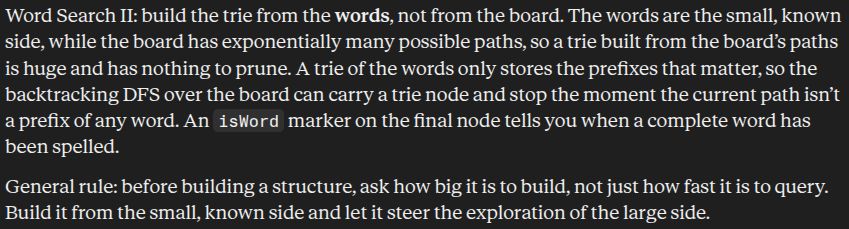

![](./drawings/word_search_II.svg)

In [ ]:
class TrieNode:
    def __init__(self):
        self.children = dict()
        self.isWord = False
        self.numberOfWordsWithPrefix = 0

class Trie:
    def __init__(self, words: List[str]):
        self.root = TrieNode()
        self.addWords(words)

        
    def addWords(self, words: List[str]):
        for word in words:
            self.addWord(word)


    def addWord(self, word: str):
        currentNode = self.root
        for character in word:
            currentNode.numberOfWordsWithPrefix += 1
            if character not in currentNode.children:
                currentNode.children[character] = TrieNode()
            currentNode = currentNode.children[character]
        currentNode.isWord = True

    def removeWord(self, word: str):
        currentNode = self.root
        for character in word:
            currentNode.numberOfWordsWithPrefix -= 1
            currentNode = currentNode.children[character]
        currentNode.isWord = False

class Solution:
    def findWords(self, board: List[List[str]], words: List[str]) -> List[str]:
        trie = Trie(words)
        numberOfRows = len(board)
        numberOfColumns = len(board[0])
        visited = set()
        foundWords = []

        def dfs(trieNode: TrieNode, currentWord: str, currentRow: int, currentColumn: int):
            if trieNode.isWord:
                foundWords.append(currentWord)
                trie.removeWord(currentWord)

            if trieNode.numberOfWordsWithPrefix == 0:
                return
            
            leftRow, leftColumn = currentRow, currentColumn - 1
            upRow, upColumn = currentRow - 1, currentColumn
            rightRow, rightColumn = currentRow, currentColumn + 1
            downRow, downColumn = currentRow + 1, currentColumn
            nextCells = [
                [leftRow, leftColumn], 
                [upRow, upColumn],
                [rightRow, rightColumn],
                [downRow, downColumn]
            ]

            for nextCell in nextCells:
                nextRow = nextCell[0]
                nextColumn = nextCell[1]

                if ((not 0 <= nextRow < numberOfRows) or 
                    (not 0 <= nextColumn < numberOfColumns) or
                    ((nextRow, nextColumn) in visited) or
                    (not board[nextRow][nextColumn] in trieNode.children)):
                    continue

                nextCharacter = board[nextRow][nextColumn]
                nextTrieNode = trieNode.children[nextCharacter]
                nextWord = currentWord + nextCharacter

                visited.add((currentRow, currentColumn))
                dfs(nextTrieNode, nextWord, nextRow, nextColumn)
                visited.remove((currentRow, currentColumn))

        for row in range(len(board)):
            for column in range(len(board[0])):
                if board[row][column] in trie.root.children:
                    dfs(trie.root.children[board[row][column]], board[row][column], row, column)

        return foundWords

In [ ]:
class Solution:
    def findWords(self, board: List[List[str]], words: List[str]) -> List[str]:
        ROWS, COLS = len(board), len(board[0])
        res = []

        def backtrack(r, c, i):
            if i == len(word):
                return True
            if (r < 0 or c < 0 or r >= ROWS or
                c >= COLS or board[r][c] != word[i]
            ):
                return False

            board[r][c] = '*'
            ret = (backtrack(r + 1, c, i + 1) or
                   backtrack(r - 1, c, i + 1) or
                   backtrack(r, c + 1, i + 1) or
                   backtrack(r, c - 1, i + 1))
            board[r][c] = word[i]
            return ret

        for word in words:
            flag = False
            for r in range(ROWS):
                if flag:
                    break
                for c in range(COLS):
                    if board[r][c] != word[0]:
                        continue
                    if backtrack(r, c, 0):
                        res.append(word)
                        flag = True
                        break
        return res

In [ ]:
class TrieNode:
    def __init__(self):
        self.children = {}
        self.isWord = False

    def addWord(self, word):
        cur = self
        for c in word:
            if c not in cur.children:
                cur.children[c] = TrieNode()
            cur = cur.children[c]
        cur.isWord = True

class Solution:
    def findWords(self, board: List[List[str]], words: List[str]) -> List[str]:
        root = TrieNode()
        for w in words:
            root.addWord(w)

        ROWS, COLS = len(board), len(board[0])
        res, visit = set(), set()

        def dfs(r, c, node, word):
            if (r < 0 or c < 0 or r >= ROWS or
                c >= COLS or (r, c) in visit or
                board[r][c] not in node.children
            ):
                return

            visit.add((r, c))
            node = node.children[board[r][c]]
            word += board[r][c]
            if node.isWord:
                res.add(word)

            dfs(r + 1, c, node, word)
            dfs(r - 1, c, node, word)
            dfs(r, c + 1, node, word)
            dfs(r, c - 1, node, word)
            visit.remove((r, c))

        for r in range(ROWS):
            for c in range(COLS):
                dfs(r, c, root, "")

        return list(res)

In [ ]:
class TrieNode:
    def __init__(self):
        self.children = [None] * 26
        self.idx = -1
        self.refs = 0

    def addWord(self, word, i):
        cur = self
        cur.refs += 1
        for c in word:
            index = ord(c) - ord('a')
            if not cur.children[index]:
                cur.children[index] = TrieNode()
            cur = cur.children[index]
            cur.refs += 1
        cur.idx = i

class Solution:
    def findWords(self, board: List[List[str]], words: List[str]) -> List[str]:
        root = TrieNode()
        for i in range(len(words)):
            root.addWord(words[i], i)

        ROWS, COLS = len(board), len(board[0])
        res = []

        def getIndex(c):
            index = ord(c) - ord('a')
            return index

        def dfs(r, c, node):
            if (r < 0 or c < 0 or r >= ROWS or
                c >= COLS or board[r][c] == '*' or
                not node.children[getIndex(board[r][c])]):
                return 0

            tmp = board[r][c]
            board[r][c] = '*'
            prev = node
            node = node.children[getIndex(tmp)]
            found = 0
            if node.idx != -1:
                res.append(words[node.idx])
                node.idx = -1
                found += 1

            found += dfs(r + 1, c, node)
            found += dfs(r - 1, c, node)
            found += dfs(r, c + 1, node)
            found += dfs(r, c - 1, node)

            board[r][c] = tmp
            node.refs -= found
            if not node.refs:
                prev.children[getIndex(tmp)] = None
            return found

        for r in range(ROWS):
            for c in range(COLS):
                root.refs -= dfs(r, c, root)

        return res